# BTC/USD — high-frequency price + 15-min realised volatility

**Cells**
1. **Config + functions** — edit the `USER CONFIG` block to change anything; everything else adapts automatically.
2. **Fetch + price plot** — pulls Binance 1s klines and Chainlink on-chain rounds, plots price.
3. **Volatility** — calendar-aligned 15-min realised vol from 1s log-returns, annualised.

In [1]:
import time, json, math
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from web3 import Web3

pd.options.display.float_format = "{:.2f}".format

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║                          USER CONFIG                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

LOOKBACK_HOURS      = 720          # how far back to fetch price data
HALF_SEC_GRID       = "500ms"    # interpolation grid for the price series
VOL_WINDOW          = "15min"    # calendar-aligned bucket size for realised vol
VOL_CALM_PCT        = 40         # annualised vol % → blue  (quiet)
VOL_HOT_PCT         = 70         # annualised vol % → red   (elevated)

SYMBOL              = "BTCUSDT"
BINANCE_URL         = "https://api.binance.com/api/v3/klines"

ETH_RPC_URL         = "https://ethereum-rpc.publicnode.com"
CHAINLINK_FEED_ADDR = "0xF4030086522a5bEEa4988F8cA5B36dbC97BeE88c"  # BTC/USD mainnet

# ── Derived (do not edit) ─────────────────────────────────────────────────────
LOOKBACK_MINUTES  = int(LOOKBACK_HOURS * 60)
SECONDS_PER_YEAR  = 60 * 60 * 24 * 365
ANNUALISE_1S      = math.sqrt(SECONDS_PER_YEAR)   # scale factor for 1s log-returns

CHAINLINK_ABI = json.loads(
    '[{"inputs":[],"name":"decimals","outputs":[{"internalType":"uint8","name":"","type":"uint8"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[],"name":"description","outputs":[{"internalType":"string","name":"","type":"string"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[],"name":"latestRoundData","outputs":[{"internalType":"uint80","name":"roundId","type":"uint80"},{"internalType":"int256","name":"answer","type":"int256"},{"internalType":"uint256","name":"startedAt","type":"uint256"},{"internalType":"uint256","name":"updatedAt","type":"uint256"},{"internalType":"uint80","name":"answeredInRound","type":"uint80"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[{"internalType":"uint80","name":"_roundId","type":"uint80"}],"name":"getRoundData","outputs":[{"internalType":"uint80","name":"roundId","type":"uint80"},{"internalType":"int256","name":"answer","type":"int256"},{"internalType":"uint256","name":"startedAt","type":"uint256"},{"internalType":"uint256","name":"updatedAt","type":"uint256"},{"internalType":"uint80","name":"answeredInRound","type":"uint80"}],"stateMutability":"view","type":"function"}]'
)

# ── Functions ─────────────────────────────────────────────────────────────────

def fetch_binance_1s_klines(
    symbol: str,
    lookback_minutes: int,
    binance_url: str,
) -> pd.DataFrame:
    now_ms        = int(time.time() * 1000)
    start_ms      = now_ms - lookback_minutes * 60 * 1000
    candles_needed = lookback_minutes * 60

    all_candles: list = []
    cursor = start_ms
    while len(all_candles) < candles_needed:
        resp = requests.get(
            binance_url,
            params={
                "symbol":    symbol,
                "interval":  "1s",
                "startTime": cursor,
                "limit":     min(1000, candles_needed - len(all_candles)),
            },
            timeout=15,
        )
        resp.raise_for_status()
        batch = resp.json()
        if not batch:
            break
        all_candles.extend(batch)
        cursor = int(batch[-1][6]) + 1  # close_time + 1ms
        time.sleep(0.05)

    df = pd.DataFrame(
        all_candles,
        columns=[
            "open_time", "open", "high", "low", "close", "volume",
            "close_time", "quote_vol", "trades", "taker_buy_base",
            "taker_buy_quote", "_ignore",
        ],
    )
    df = df.drop_duplicates(subset=["open_time"], keep="last")
    df["timestamp"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    for col in ["open", "high", "low", "close", "volume"]:
        df[col] = df[col].astype(float)
    return df[["timestamp", "open", "high", "low", "close", "volume"]].reset_index(drop=True)


def interpolate_to_grid(klines_1s: pd.DataFrame, grid_freq: str) -> pd.DataFrame:
    ts = klines_1s.set_index("timestamp")[["close"]].rename(columns={"close": "price_usd"})
    grid_idx = pd.date_range(
        start=ts.index.min(),
        end=ts.index.max() + pd.Timedelta(grid_freq),
        freq=grid_freq,
        tz="UTC",
    )
    resampled = ts.reindex(ts.index.union(grid_idx)).sort_index()
    resampled["price_usd"] = resampled["price_usd"].interpolate(method="time")
    return (
        resampled.loc[grid_idx]
        .dropna()
        .reset_index()
        .rename(columns={"index": "timestamp"})
    )


def fetch_chainlink_reference(
    lookback_minutes: int,
    rpc_url: str,
    feed_address: str,
    abi: list,
) -> pd.DataFrame:
    w3       = Web3(Web3.HTTPProvider(rpc_url, request_kwargs={"timeout": 30}))
    contract = w3.eth.contract(address=Web3.to_checksum_address(feed_address), abi=abi)
    decimals = contract.functions.decimals().call()

    latest_round_id, latest_answer, _, latest_updated_at, _ = (
        contract.functions.latestRoundData().call()
    )
    cutoff_ts = int((datetime.now(timezone.utc) - timedelta(minutes=lookback_minutes)).timestamp())
    phase_id  = int(latest_round_id) >> 64
    agg_round = int(latest_round_id) & ((1 << 64) - 1)

    rows = [{"updated_at": int(latest_updated_at), "price_usd": float(latest_answer) / 10 ** decimals}]
    cur = agg_round - 1
    while cur >= 1:
        try:
            _, answer, _, updated_at, _ = contract.functions.getRoundData((phase_id << 64) | cur).call()
        except Exception:
            cur -= 1
            continue
        if int(updated_at) == 0:
            cur -= 1
            continue
        rows.append({"updated_at": int(updated_at), "price_usd": float(answer) / 10 ** decimals})
        if int(updated_at) < cutoff_ts:
            break
        cur -= 1

    df = pd.DataFrame(rows)
    df["updated_at"] = pd.to_datetime(df["updated_at"], unit="s", utc=True)
    return df.sort_values("updated_at").drop_duplicates().reset_index(drop=True)


def realized_vol(
    klines_1s: pd.DataFrame,
    vol_window: str,
    annualise_factor: float,
) -> pd.DataFrame:
    df = (
        klines_1s[["timestamp", "close"]]
        .rename(columns={"close": "price_usd"})
        .set_index("timestamp")
        .sort_index()
    )
    df["window"]  = df.index.floor(vol_window)
    df["log_ret"] = np.log(df["price_usd"]).diff()
    first_in_window = df.groupby("window").cumcount() == 0
    df.loc[first_in_window, "log_ret"] = np.nan

    vol = (
        df.groupby("window")["log_ret"]
        .std()
        .mul(annualise_factor)
        .mul(100)
        .rename("vol_pct")
        .reset_index()
    )
    vol["n_ticks"] = df.groupby("window").size().values
    return vol


print(f"Config loaded — lookback={LOOKBACK_HOURS}h  grid={HALF_SEC_GRID}  vol_window={VOL_WINDOW}")

Config loaded — lookback=720h  grid=500ms  vol_window=15min


Fetching Binance 1s klines  (720h, BTCUSDT) …
  → 2592000 one-second candles
Interpolating to 500ms grid …
  → 5184000 samples
Fetching Chainlink on-chain rounds …
  → 1131 Chainlink round(s)


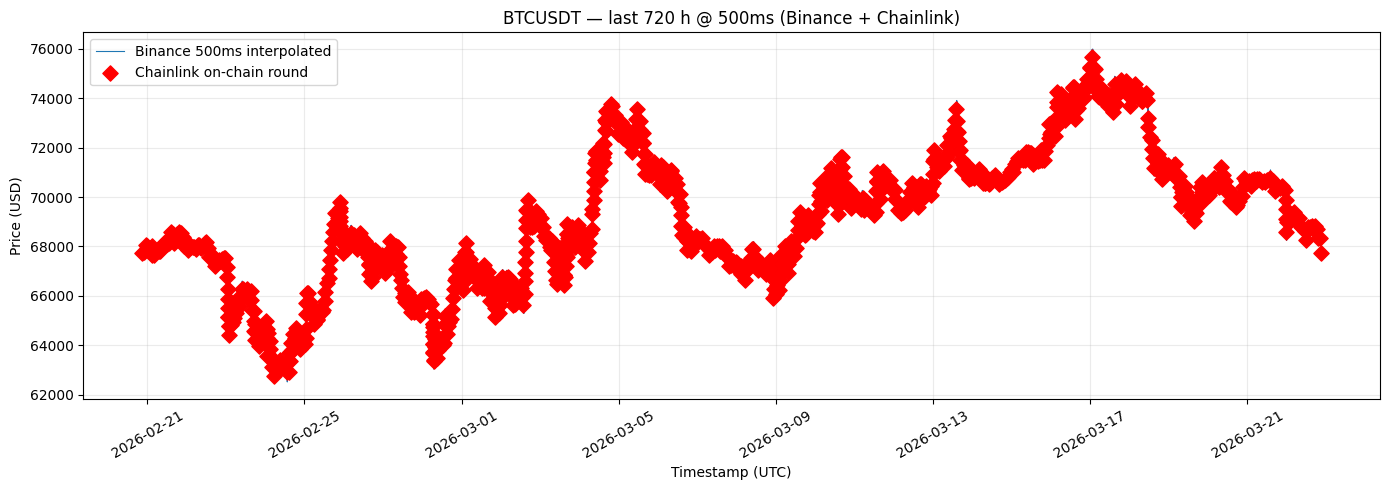

In [2]:
# ── Fetch ─────────────────────────────────────────────────────────────────────
print(f"Fetching Binance 1s klines  ({LOOKBACK_HOURS}h, {SYMBOL}) …")
klines_1s = fetch_binance_1s_klines(
    symbol=SYMBOL,
    lookback_minutes=LOOKBACK_MINUTES,
    binance_url=BINANCE_URL,
)
print(f"  → {len(klines_1s)} one-second candles")

print(f"Interpolating to {HALF_SEC_GRID} grid …")
btc_grid = interpolate_to_grid(klines_1s, grid_freq=HALF_SEC_GRID)
print(f"  → {len(btc_grid)} samples")

print("Fetching Chainlink on-chain rounds …")
chainlink_ref = fetch_chainlink_reference(
    lookback_minutes=LOOKBACK_MINUTES,
    rpc_url=ETH_RPC_URL,
    feed_address=CHAINLINK_FEED_ADDR,
    abi=CHAINLINK_ABI,
)
print(f"  → {len(chainlink_ref)} Chainlink round(s)")

# ── Plot: price ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(btc_grid["timestamp"], btc_grid["price_usd"],
        linewidth=0.8, label=f"Binance {HALF_SEC_GRID} interpolated")
ax.scatter(chainlink_ref["updated_at"], chainlink_ref["price_usd"],
           color="red", s=60, zorder=5, marker="D", label="Chainlink on-chain round")
ax.set_title(f"{SYMBOL} — last {LOOKBACK_HOURS} h @ {HALF_SEC_GRID} (Binance + Chainlink)")
ax.set_xlabel("Timestamp (UTC)")
ax.set_ylabel("Price (USD)")
ax.legend()
ax.grid(alpha=0.25)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

15min windows : 2881
Vol range : 5.1% – 173.9%
Vol mean  : 40.2%
(BTC typical: 40–80% normal | >80% elevated | <30% very quiet)



'                   window  vol_pct  n_ticks\n2026-02-20 21:00:00+00:00    34.97      851\n2026-02-20 21:15:00+00:00    18.65      900\n2026-02-20 21:30:00+00:00    20.70      900\n2026-02-20 21:45:00+00:00    15.53      900\n2026-02-20 22:00:00+00:00    22.87      900\n2026-02-20 22:15:00+00:00    48.45      900\n2026-02-20 22:30:00+00:00    42.86      900\n2026-02-20 22:45:00+00:00    33.00      900\n2026-02-20 23:00:00+00:00    40.26      900\n2026-02-20 23:15:00+00:00    20.98      900\n2026-02-20 23:30:00+00:00    25.25      900\n2026-02-20 23:45:00+00:00    19.00      900\n2026-02-21 00:00:00+00:00    23.79      900\n2026-02-21 00:15:00+00:00    20.14      900\n2026-02-21 00:30:00+00:00    18.09      900\n2026-02-21 00:45:00+00:00    20.43      900\n2026-02-21 01:00:00+00:00    19.25      900\n2026-02-21 01:15:00+00:00    11.47      900\n2026-02-21 01:30:00+00:00    16.06      900\n2026-02-21 01:45:00+00:00     9.58      900\n2026-02-21 02:00:00+00:00    14.13      900\n2026-02-2

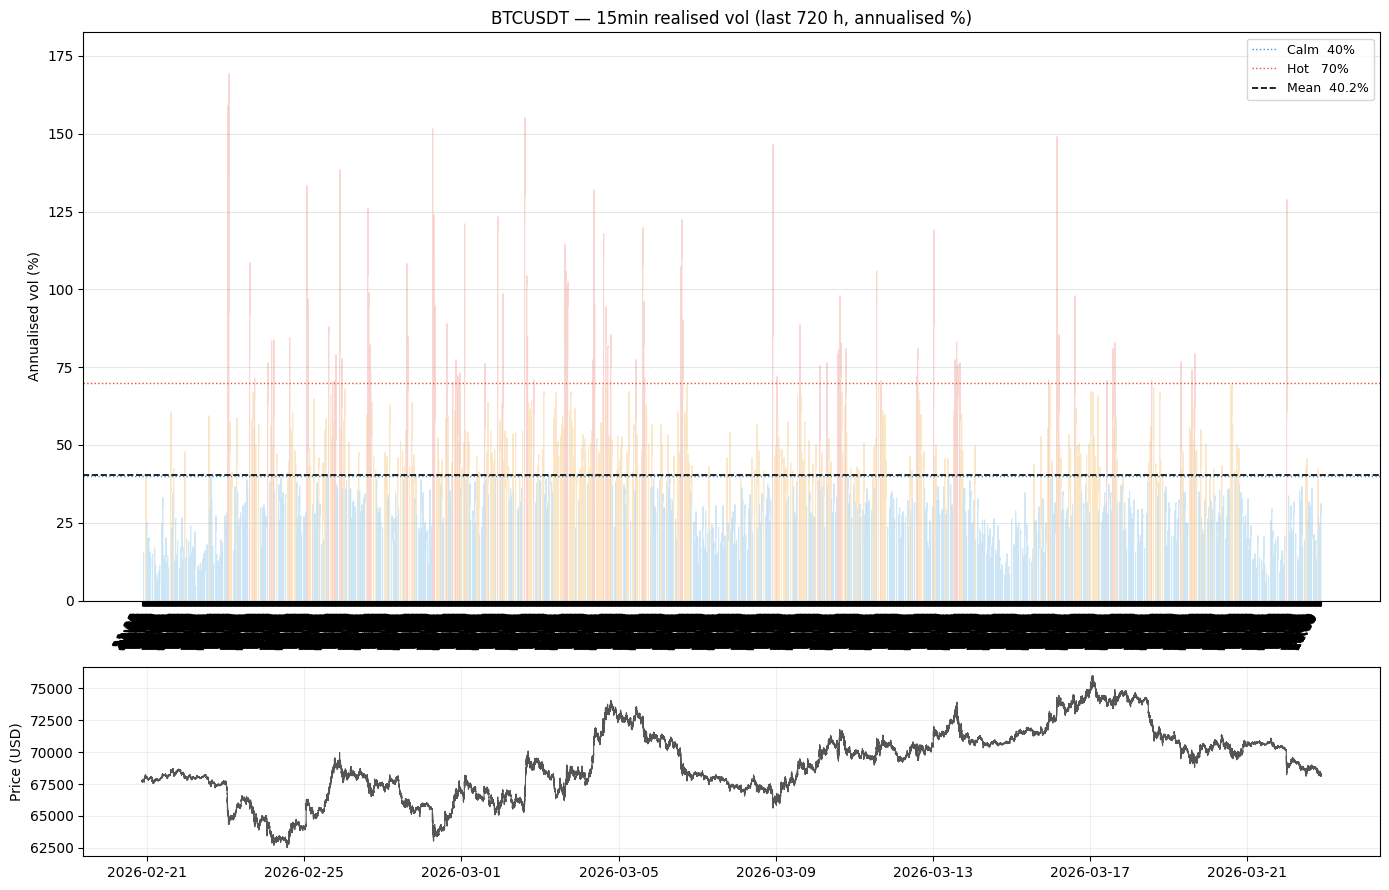

,window,vol_pct,n_ticks
0,2026-02-20 21:00:00+00:00,34.97,851
1,2026-02-20 21:15:00+00:00,18.65,900
2,2026-02-20 21:30:00+00:00,20.70,900
3,2026-02-20 21:45:00+00:00,15.53,900
4,2026-02-20 22:00:00+00:00,22.87,900
...,...,...,...
2876,2026-03-22 20:00:00+00:00,30.20,900
2877,2026-03-22 20:15:00+00:00,24.56,900
2878,2026-03-22 20:30:00+00:00,24.27,900
2879,2026-03-22 20:45:00+00:00,31.43,900


In [3]:
# ── Realised vol ─────────────────────────────────────────────────────────────
vol_df = realized_vol(
    klines_1s=klines_1s,
    vol_window=VOL_WINDOW,
    annualise_factor=ANNUALISE_1S,
)

print(f"{VOL_WINDOW} windows : {len(vol_df)}")
print(f"Vol range : {vol_df['vol_pct'].min():.1f}% – {vol_df['vol_pct'].max():.1f}%")
print(f"Vol mean  : {vol_df['vol_pct'].mean():.1f}%")
print(f"(BTC typical: 40–80% normal | >80% elevated | <30% very quiet)\n")
display(vol_df.to_string(index=False))

# ── Plot ──────────────────────────────────────────────────────────────────────
def _bar_color(v, calm, hot):
    if v >= hot:   return "#e74c3c"
    if v >= calm:  return "#f39c12"
    return "#3498db"

bar_colors  = [_bar_color(v, VOL_CALM_PCT, VOL_HOT_PCT) for v in vol_df["vol_pct"]]
bar_width   = pd.Timedelta(VOL_WINDOW) * 0.85

fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [3, 1]})

ax = axes[0]
ax.bar(vol_df["window"], vol_df["vol_pct"], width=bar_width,
       color=bar_colors, edgecolor="white", linewidth=0.4)
ax.axhline(VOL_CALM_PCT, color="#3498db", linestyle=":", linewidth=1,
           label=f"Calm  {VOL_CALM_PCT}%")
ax.axhline(VOL_HOT_PCT,  color="#e74c3c", linestyle=":", linewidth=1,
           label=f"Hot   {VOL_HOT_PCT}%")
ax.axhline(vol_df["vol_pct"].mean(), color="black", linestyle="--", linewidth=1.2,
           label=f"Mean  {vol_df['vol_pct'].mean():.1f}%")
ax.set_title(f"{SYMBOL} — {VOL_WINDOW} realised vol (last {LOOKBACK_HOURS} h, annualised %)")
ax.set_ylabel("Annualised vol (%)")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
ax.set_xticks(vol_df["window"])
ax.set_xticklabels([t.strftime("%H:%M") for t in vol_df["window"]], rotation=60, ha="right")

axes[1].plot(klines_1s["timestamp"], klines_1s["close"], linewidth=0.8, color="#555")
axes[1].set_ylabel("Price (USD)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

vol_df

In [ ]:
# ── Load pre-collected historical data ────────────────────────────────────────
# Run  `python btc_collector.py`  once from the terminal first.
# Then use this cell instead of fetch_binance_1s_klines() for big date ranges.

import sys
sys.path.insert(0, str(__import__("pathlib").Path("__file__").parent))
from btc_collector import load_btc_price

# Load everything saved (last 4 months, 0.5s grid by default)
btc_hist = load_btc_price()

# Slice to a specific date range
# btc_hist = load_btc_price(start="2025-12-01", end="2026-01-31")

# Keep 1-second resolution instead of 0.5s
# btc_hist = load_btc_price(grid_freq="1s")

print("Uncomment a line above and run to load stored data.")